In [1]:
import os
import numpy as np
os.environ["KERAS_BACKEND"] = "jax"
import keras
from keras import layers
from datasets import load_dataset

In [2]:
dataset = load_dataset("zalando-datasets/fashion_mnist")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


In [ ]:

print(dataset["train"]["label"])
# print(dataset["train"].features)
# print(dataset["train"][0])
x = np.array(dataset["train"]["label"])
print(x.shape)
print(x.dtype)
print(x.min())
print(x.max())

In [ ]:

print(dataset["train"]["image"])
# print(dataset["train"].features)
# print(dataset["train"][0])
x = np.array(dataset["train"]["image"])
print(x.shape)
print(x.dtype)
print(x.min())
print(x.max())

Formattazione dei samples

In [3]:
# Creo un tensore train_image con le immagini del dataset
# ne modifico la forma, avendo 60000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

x = np.array(dataset["train"]["image"])

train_images = x.reshape((60000, 28 * 28))
train_images= train_images.astype("float32")
train_images /= 255.0

train_labels = np.array(dataset["train"]["label"])

print("------TRAINING SAMPLES-------")
print(train_images.shape)
print(train_images.dtype)
print(train_images.min())
print(train_images.max())

print("------TRAINING LABELS-------")
print(train_labels.shape)
print(train_labels.dtype)
print(train_labels.min())
print(train_labels.max())


# Creo un tensore tratest_images con le immagini del dataset
# ne modifico la forma, avendo 10000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

y = np.array(dataset["test"]["image"])

test_images = y.reshape((10000, 28 * 28))
test_images= test_images.astype("float32")
test_images /= 255.0

test_labels = np.array(dataset["test"]["label"])

print("------TEST SAMPLES-------")
print(test_images.shape)
print(test_images.dtype)
print(test_images.min())
print(test_images.max())

print("------TEST LABELS-------")
print(test_labels.shape)
print(test_labels.dtype)
print(test_labels.min())
print(test_labels.max())


------TRAINING SAMPLES-------
(60000, 784)
float32
0.0
1.0
------TRAINING LABELS-------
(60000,)
int64
0
9
------TEST SAMPLES-------
(10000, 784)
float32
0.0
1.0
------TEST LABELS-------
(10000,)
int64
0
9


-----------MODEL SUMMARY-----------


Model: "Fashion_MNIST_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Uno (Dense)                     │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,002 (3.10 MB)

 Trainable params: 813,002 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

-----------MODEL LAYERS-------------
0 Input_layer InputLayer
1 Uno Dense
2 dense Dense
3 dense_1 Dense
4 dense_2 Dense
5 dense_3 Dense
Epoch 1/20


/opt/miniconda3/envs/ai_env/lib/python3.12/site-packages/jax/_src/core.py:1976: UserWarning: Explicitly requested dtype int64 requested in ShapeDtypeStruct is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return aval_fn(x)


384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8142 - loss: 0.5198 - val_accuracy: 0.8373 - val_loss: 0.4384
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8663 - loss: 0.3650 - val_accuracy: 0.8685 - val_loss: 0.3722
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8775 - loss: 0.3327 - val_accuracy: 0.8648 - val_loss: 0.3665
Epoch 4/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8866 - loss: 0.3028 - val_accuracy: 0.8708 - val_loss: 0.3656
Epoch 5/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8922 - loss: 0.2882 - val_accuracy: 0.8802 - val_loss: 0.3318
Epoch 6/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8995 - loss: 0.2682 - val_accuracy: 0.8872 - val_loss: 0.3252
Epoch 7/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9030 - loss: 0.2568 - val_accuracy: 0.8851 - val_loss: 0.3305
Epoch 8/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9076 - loss: 0.2446 - val_accuracy: 0.8850 - val_

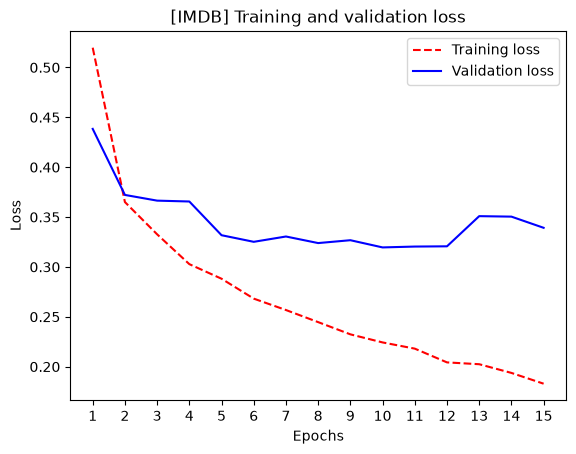

In [4]:
# model = keras.Sequential(
#     [
#         keras.Input(shape=(28*28,)),
#         layers.Dense(512, activation="relu"),
#         layers.Dense(512, activation="relu"),
#         layers.Dense(256, activation="relu"),
#         layers.Dense(256, activation="relu"),
#         layers.Dense(10, activation="softmax"),
#     ]
# )
keras.utils.set_random_seed(42)

inputs = keras.Input(shape=(28*28,), name = "Input_layer")
features_1 = layers.Dense(512, activation="relu", name="Uno")(inputs)
features_2 = layers.Dense(512, activation="relu")(features_1)
features_3 = layers.Dense(256, activation="relu")(features_2)
features_4 = layers.Dense(64, activation="relu")(features_3)
output = layers.Dense(10, activation="softmax")(features_4)


model = keras.Model(
    inputs = inputs,
    outputs = output,
    name = "Fashion_MNIST_model"
)

print("-----------MODEL SUMMARY-----------")
model.summary()

print("-----------MODEL LAYERS-------------")
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.__class__.__name__)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience=5,
    restore_best_weights=True
)

tensorboard = keras.callbacks.TensorBoard(
    log_dir = "logs"
)


history = model.fit(
    train_images,
    train_labels,
    epochs=20,
    batch_size=125,
    validation_split=0.2,
    callbacks = [early_stopping, tensorboard]
    )


import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "r--", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("[IMDB] Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("[IMDB] Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_images,
    test_labels,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

In [ ]:
print(f"Ultima training accuracy: "
      f"{history.history['accuracy'][-1]:.2%}")

print(f"Ultima validation accuracy: "
      f"{history.history['val_accuracy'][-1]:.2%}")

print(f"Migliore validation accuracy: "
      f"{max(history.history['val_accuracy']):.2%}")

In [ ]:
import numpy as np

best_epoch = np.argmin(history.history["val_loss"])

print(f"Epoca migliore: {best_epoch + 1}")
print(
    "Validation loss minima:",
    history.history["val_loss"][best_epoch]
)
print(
    "Validation accuracy in quell'epoca:",
    f"{history.history['val_accuracy'][best_epoch]:.2%}"
)

In [ ]:
best_epoch = np.argmin(history.history["val_loss"]) + 1

print(f"Epoche eseguite: {len(history.history['loss'])}")
print(f"Epoca migliore: {best_epoch}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

BASELINE INIZIALE SENZA SEED


Architettura del modello: 

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Uno (Dense)                     │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 813,002 (3.10 MB)
 Trainable params: 813,002 (3.10 MB)
 Non-trainable params: 0 (0.00 B)

Numero di epoche eseguite: 16

Epoca con la validation loss minima: 11

training Loss e Validatin Loss dell'epoca: training_loss= 0.2171 val_loss=0.3045

Valutazione curve: a training loss continua a diminuire, mentre la validation loss oscilla senza migliorare il minimo dell’epoca 11. Questo suggerisce overfitting, anche se la validation loss non cresce a ogni epoca

